# Episode 7: The Loss, by Hand
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/Episode%2007%20-%20The%20Loss%2C%20by%20Hand/notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*. What Learning Means, part 1 of 2.

The episode works every calculation by hand. This notebook does the same calculations in the same order, prints each line the way it appears on screen, and checks every value with an `assert`. It uses only `numpy` and `matplotlib` (both already in Colab), plus Python's built-in `fractions` so the thirds and sixths print exactly: choose **Runtime, Run all**.

| Part | What you'll compute | Video numbers |
|---|---|---|
| 1 | The knobs and the data: ŷ = Wu + β on three points | (1, 2), (2, 4), (3, 5) · N = 3 |
| 2 | Mean squared error by hand for three lines, the least-squares check, and a picture of the gaps and their squares | A: 1/3 ≈ 0.333 · B: 1/18 ≈ 0.056 · C: 1/12 ≈ 0.083 |
| 3 | Cross-entropy with a one-hot target, ln 0.30 by hand, a second word, the mean, and perplexity | 1.204 · 0.511 · 0.857 · 2.36 |
| 4 | The bet payouts, the myth "the loss counts wrong answers", and the check question | 0.105 · 0.693 · 2.303 · 4.605 · 0.799 · 1.040 → 0.805 |
| 5 | Try it yourself, with self-checks | your numbers |

Episode 1's four-word probabilities (mat 0.30, floor 0.20, sofa 0.15, other 0.35, after “The cat sat on the”) are **illustrative**, and so are the three data points. Logs are natural (nats).

## Setup

In [1]:
from fractions import Fraction as F

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

STEEL, GOLD, CORAL, MUTED = "#8FB4E8", "#FFC400", "#FF4D3D", "#8B98AE"   # the video's colours
DOT = "#1B2A4A"                                                          # the data points (white on the video's navy)

words = ["mat", "floor", "sofa", "other"]
p = np.array([0.30, 0.20, 0.15, 0.35])        # illustrative, from Episode 1


def fmt(x):
    """Print a number the way you would write it on paper: 0.64, not 0.6400000000000001."""
    return f"{round(float(x), 8):.10g}"


def frac(x, sign=False):
    """An exact Fraction written as on the worksheet: 13/6, -1/6, +1/3."""
    s = str(F(x))
    return f"+{s}" if sign and x > 0 else s


def surprisal(x):
    """-ln p, in nats (Episode 4)."""
    return -np.log(x)

## Part 1 · A model is a function with knobs

Episode 3's linear layer: **ŷ = Wu + β**. The input is u, the prediction is ŷ, and W and β are the knobs. In a language model there are millions of knobs, and together they are called θ.

**Training** changes θ. **Inference** runs the model with θ held fixed. Learning means one thing: turning the knobs to make one number small, the **loss**.

The smallest data set: three examples (u, y). Each right answer y is the **label**.

In [2]:
u = np.array([1, 2, 3])
y = np.array([2, 4, 5])
N = len(u)


def predict(W, beta, x=u):
    """y-hat = W u + beta: one weight, one bias, two knobs."""
    return W * x + beta


print(" u | y (label)")
for ui, yi in zip(u, y):
    print(f" {ui} | {yi}")
print(f"N = {N} examples, two knobs: W and beta")
assert N == 3 and list(zip(u, y)) == [(1, 2), (2, 4), (3, 5)]

 u | y (label)
 1 | 2
 2 | 4
 3 | 5
N = 3 examples, two knobs: W and beta


## Part 2 · The loss for numbers: mean squared error

For each example: predict, take the error (label minus prediction), square it. Add the squares and divide by N:

**L(θ) = (1/N) Σ (yᵢ − ŷᵢ)²**

Why square? A miss below and a miss above shouldn't cancel out. Squared, every gap counts as a positive penalty. `mse_by_hand` prints the video's worksheet with exact fractions, then checks the result in floating point.

### Step 1: line A, W = 2, β = 0

In [3]:
def mse_by_hand(name, W, beta, W_txt, beta_txt):
    W, beta = F(W), F(beta)
    print(f"Line {name}: W = {W_txt}, beta = {beta_txt}")
    preds, errs, sqs = [], [], []
    for ui, yi in zip(u, y):
        yhat = W * int(ui) + beta
        Wu = W * int(ui)
        mid = f" = {fmt(float(Wu))} + {beta_txt}" if beta.denominator > 1 else ""
        print(f"  u = {ui}: y-hat = {W_txt} x {ui} + {beta_txt}{mid} = {frac(yhat)}")
        preds.append(yhat)
    for yi, yhat in zip(y, preds):
        e = int(yi) - yhat
        errs.append(e)
        print(f"  error: {yi} - {frac(yhat)} = {frac(e, sign=e > 0 and beta.denominator > 1)}")
    for e in errs:
        s = e * e
        sqs.append(s)
        base = f"({frac(e)})" if e < 0 or e.denominator > 1 else frac(e)
        print(f"  square: {base}^2 = {frac(s)}")
    total = sum(sqs)
    D = np.lcm.reduce([s.denominator for s in sqs])
    if any(s and s.denominator != D for s in sqs):      # show the squares over one denominator, as on screen
        common = " + ".join(f"{s.numerator * (D // s.denominator)}/{D}" for s in sqs)
        top = sum(s.numerator * (D // s.denominator) for s in sqs)
        print(f"  add: {' + '.join(frac(s) for s in sqs)} = {common} = {top}/{D} = {frac(total)}")
    else:
        print(f"  add: {' + '.join(frac(s) for s in sqs)} = {frac(total)}")
    L = total / N
    tt = f"({frac(total)})" if total.denominator > 1 else frac(total)
    print(f"  divide by N = {N}: MSE = {tt} / {N} = {frac(L)} ~ {float(L):.3f}\n")
    assert np.isclose(float(L), np.mean((y - predict(float(W), float(beta))) ** 2))
    return preds, errs, sqs, L


predsA, errsA, sqsA, LA = mse_by_hand("A", 2, 0, "2", "0")
assert predsA == [2, 4, 6] and errsA == [0, 0, -1] and sqsA == [0, 0, 1] and sum(sqsA) == 1
assert LA == F(1, 3) and round(float(LA), 3) == 0.333
print("Two perfect hits and one miss.")

Line A: W = 2, beta = 0
  u = 1: y-hat = 2 x 1 + 0 = 2
  u = 2: y-hat = 2 x 2 + 0 = 4
  u = 3: y-hat = 2 x 3 + 0 = 6
  error: 2 - 2 = 0
  error: 4 - 4 = 0
  error: 5 - 6 = -1
  square: 0^2 = 0
  square: 0^2 = 0
  square: (-1)^2 = 1
  add: 0 + 0 + 1 = 1
  divide by N = 3: MSE = 1 / 3 = 1/3 ~ 0.333

Two perfect hits and one miss.


### Step 2: line B, W = 1.5, β = 2/3
These knobs look oddly specific. Hang on to that.

In [4]:
predsB, errsB, sqsB, LB = mse_by_hand("B", F(3, 2), F(2, 3), "1.5", "2/3")
assert predsB == [F(13, 6), F(11, 3), F(31, 6)]
assert errsB == [F(-1, 6), F(1, 3), F(-1, 6)]
assert sqsB == [F(1, 36), F(1, 9), F(1, 36)] and F(1, 9) == F(4, 36)
assert sum(sqsB) == F(6, 36) == F(1, 6)
assert LB == F(1, 18) and round(float(LB), 3) == 0.056
assert LA / LB == 6
print(f"Line B misses every dot, and its loss is {fmt(LA / LB)} times smaller than line A's.")

Line B: W = 1.5, beta = 2/3
  u = 1: y-hat = 1.5 x 1 + 2/3 = 1.5 + 2/3 = 13/6
  u = 2: y-hat = 1.5 x 2 + 2/3 = 3 + 2/3 = 11/3
  u = 3: y-hat = 1.5 x 3 + 2/3 = 4.5 + 2/3 = 31/6
  error: 2 - 13/6 = -1/6
  error: 4 - 11/3 = +1/3
  error: 5 - 31/6 = -1/6
  square: (-1/6)^2 = 1/36
  square: (1/3)^2 = 1/9
  square: (-1/6)^2 = 1/36
  add: 1/36 + 1/9 + 1/36 = 1/36 + 4/36 + 1/36 = 6/36 = 1/6
  divide by N = 3: MSE = (1/6) / 3 = 1/18 ~ 0.056

Line B misses every dot, and its loss is 6 times smaller than line A's.


### Step 3: line B is the least-squares fit
No other W and β gives a smaller mean squared error for these three points. Two checks: `np.polyfit` (which solves the least-squares problem directly) and a brute-force grid of 150,801 knob settings.

In [5]:
W_fit, beta_fit = np.polyfit(u, y, 1)
print(f"np.polyfit: W = {W_fit:.4f}, beta = {beta_fit:.4f}   (2/3 = {2 / 3:.4f})")
assert np.isclose(W_fit, 1.5) and np.isclose(beta_fit, 2 / 3)

Ws = np.linspace(0, 3, 301)                    # steps of 0.01
bs = np.linspace(-2, 3, 501)                   # steps of 0.01
WW, BB = np.meshgrid(Ws, bs, indexing="ij")
grid = ((y[None, None, :] - (WW[..., None] * u + BB[..., None])) ** 2).mean(axis=-1)
i, j = np.unravel_index(np.argmin(grid), grid.shape)
print(f"grid of {grid.size:,} settings: lowest MSE {grid.min():.4f} at W = {Ws[i]:.2f}, beta = {bs[j]:.2f}")
print(f"no setting beats 1/18 = {1 / 18:.4f}")
assert grid.size == 150801 and grid.min() >= 1 / 18 - 1e-12
assert np.isclose(Ws[i], 1.5) and abs(bs[j] - 2 / 3) <= 0.005

np.polyfit: W = 1.5000, beta = 0.6667   (2/3 = 0.6667)
grid of 150,801 settings: lowest MSE 0.0556 at W = 1.50, beta = 0.67
no setting beats 1/18 = 0.0556


### Step 4: one more by hand, line C: W = 1.5, β = 1/2

In [6]:
predsC, errsC, sqsC, LC = mse_by_hand("C", F(3, 2), F(1, 2), "1.5", "1/2")
assert predsC == [2, F(7, 2), 5] and errsC == [0, F(1, 2), 0]
assert LC == F(1, 12) and round(float(LC), 3) == 0.083 and LB < LC < LA
print("Still worse than line B.")

Line C: W = 1.5, beta = 1/2
  u = 1: y-hat = 1.5 x 1 + 1/2 = 1.5 + 1/2 = 2
  u = 2: y-hat = 1.5 x 2 + 1/2 = 3 + 1/2 = 7/2
  u = 3: y-hat = 1.5 x 3 + 1/2 = 4.5 + 1/2 = 5
  error: 2 - 2 = 0
  error: 4 - 7/2 = +1/2
  error: 5 - 5 = 0
  square: 0^2 = 0
  square: (1/2)^2 = 1/4
  square: 0^2 = 0
  add: 0 + 1/4 + 0 = 1/4
  divide by N = 3: MSE = (1/4) / 3 = 1/12 ~ 0.083

Still worse than line B.


### One picture of the three lines
Each gap is a coral segment from the line to the dot, and its **square** is drawn beside it with side |gap|. The mean squared error is the average area of the coral squares. Line A has one big square; line B has three small ones, and their total is smaller.

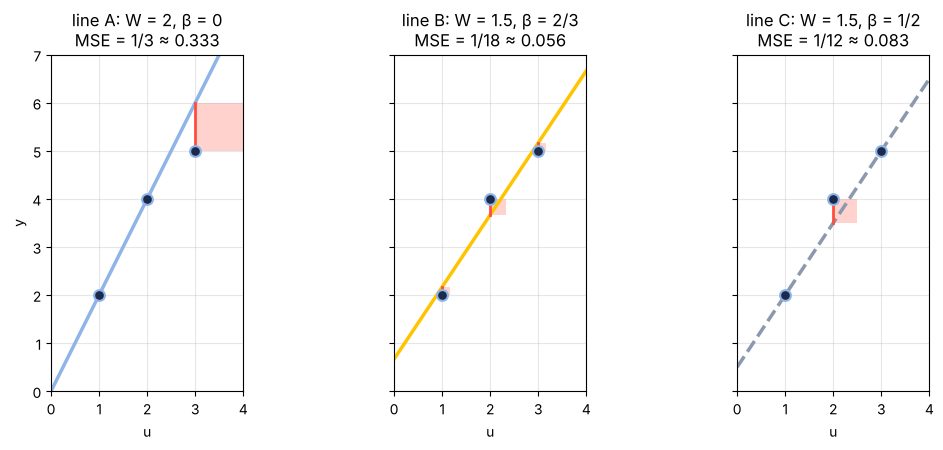

In [7]:
lines = [("A", 2, 0, STEEL, "-", LA), ("B", 1.5, 2 / 3, GOLD, "-", LB), ("C", 1.5, 0.5, MUTED, "--", LC)]
fig, axes = plt.subplots(1, 3, figsize=(11, 4.6), sharey=True)
xs = np.array([0, 4])
for ax, (name, W, b, col, ls, L) in zip(axes, lines):
    ax.plot(xs, predict(W, b, xs), ls, color=col, lw=2.5)
    for ui, yi in zip(u, y):
        yh = predict(W, b, ui)
        gap = yi - yh
        if abs(gap) > 1e-9:
            ax.plot([ui, ui], [yh, yi], color=CORAL, lw=2)
            ax.add_patch(Rectangle((ui, min(yh, yi)), abs(gap), abs(gap), color=CORAL, alpha=0.25, lw=0))
    ax.scatter(u, y, s=60, color=DOT, edgecolor=STEEL, linewidth=1.5, zorder=3)
    ax.set_title(f"line {name}: W = {fmt(W) if name == 'A' else '1.5'}, β = {['0', '2/3', '1/2'][ord(name) - 65]}\nMSE = {frac(L)} ≈ {float(L):.3f}")
    ax.set_xlim(0, 4); ax.set_ylim(0, 7); ax.set_aspect("equal")
    ax.set_xlabel("u"); ax.grid(alpha=0.3)
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

**Darts.** Each throw lands some distance from the bullseye. Square that distance and average over your throws: that is the mean squared error. Line A hits the bullseye twice and then misses by a lot; line B lands close every time. Squaring makes the big miss expensive: line A's one miss of 1 costs 1, while line B's three misses together cost only 1/6.

In [8]:
print(f"line A: one miss of 1     -> squares add to {frac(sum(sqsA))}")
print(f"line B: misses of 1/6, 1/3, 1/6 -> squares add to {frac(sum(sqsB))}")
print(f"line B's misses add to {frac(sum(abs(e) for e in errsB))} in distance, but squared they cost {frac(sum(sqsB))}")
assert sum(abs(e) for e in errsB) == F(2, 3) and sum(sqsB) < sum(sqsA)

line A: one miss of 1     -> squares add to 1
line B: misses of 1/6, 1/3, 1/6 -> squares add to 1/6
line B's misses add to 2/3 in distance, but squared they cost 1/6


## Part 3 · The loss for words: cross-entropy

A language model predicts a word, not a number. After “The cat sat on the”, the model hands out probabilities (illustrative, from Episode 1), and the data say the next word was **mat**. Write that as a target q that puts all its weight on the observed word: 1 for mat, 0 for the rest (a **one-hot** target).

Episode 4's cross-entropy: **H(q, p) = −Σ q ln p**.

### Step 5: write out the four terms

In [9]:
q = np.array([1, 0, 0, 0])
for w, pk, qk in zip(words, p, q):
    print(f"{w:6s} p = {pk:.2f}   q = {qk}")
terms = " + ".join(f"{qk} x ln {pk:.2f}" for qk, pk in zip(q, p))
H = -np.sum(q * np.log(p))
print(f"\nH(q, p) = -({terms})")
print(f"        = -ln 0.30 = {H:.3f}")
assert np.isclose(p.sum(), 1) and q.sum() == 1 and np.isclose(H, -np.log(0.30))
print("Every term but one is multiplied by zero: the cross-entropy is minus the log of the probability on the observed word.")

mat    p = 0.30   q = 1
floor  p = 0.20   q = 0
sofa   p = 0.15   q = 0
other  p = 0.35   q = 0

H(q, p) = -(1 x ln 0.30 + 0 x ln 0.20 + 0 x ln 0.15 + 0 x ln 0.35)
        = -ln 0.30 = 1.204
Every term but one is multiplied by zero: the cross-entropy is minus the log of the probability on the observed word.


### Step 6: −ln 0.30 by hand
0.3 is 3 over 10, so ln 0.3 = ln 3 − ln 10.

In [10]:
ln3, ln10 = np.log(3), np.log(10)
print(f"ln 3  ~ {ln3:.3f}")
print(f"ln 10 ~ {ln10:.3f}")
print(f"ln 0.30 = ln 3 - ln 10 ~ {ln3:.3f} - {ln10:.3f} = {round(ln3, 3) - round(ln10, 3):.3f}")
s_mat = surprisal(0.30)
print(f"flip the sign: -ln 0.30 = {s_mat:.3f} nats   (mat's surprisal, the same number as Episode 4)")
assert round(ln3, 3) == 1.099 and round(ln10, 3) == 2.303
assert np.isclose(round(ln3, 3) - round(ln10, 3), -1.204) and round(s_mat, 3) == 1.204
assert np.isclose(np.log(0.3), ln3 - ln10)

ln 3  ~ 1.099
ln 10 ~ 2.303
ln 0.30 = ln 3 - ln 10 ~ 1.099 - 2.303 = -1.204
flip the sign: -ln 0.30 = 1.204 nats   (mat's surprisal, the same number as Episode 4)


### Step 7: one term versus the loss
One word is one term; training averages many. Suppose the next observed word got probability 0.60. Then average the two terms (N = 2):

**L(θ) = (1/N) Σ −ln p_θ(observed token)**

In [11]:
ln6 = np.log(6)
s_2 = surprisal(0.60)
print(f"-ln 0.60 = -(ln 6 - ln 10) = -({ln6:.3f} - {ln10:.3f}) = {s_2:.3f} nats")
total = s_mat + s_2
L_words = total / 2
print(f"loss: ({s_mat:.3f} + {s_2:.3f}) / 2 = {total:.3f} / 2 = {L_words:.3f} nats")
assert round(ln6, 3) == 1.792 and np.isclose(round(ln10, 3) - round(ln6, 3), 0.511) and round(s_2, 3) == 0.511
assert round(total, 3) == 1.715 and round(L_words, 3) == 0.857
print("1.204 is one term. The loss is the average.")

-ln 0.60 = -(ln 6 - ln 10) = -(1.792 - 2.303) = 0.511 nats
loss: (1.204 + 0.511) / 2 = 1.715 / 2 = 0.857 nats
1.204 is one term. The loss is the average.


### Step 8: loss and perplexity
Episode 4's perplexity is e raised to the mean surprisal. Because the mean of the logs is the log of the geometric mean, e^L is also 1 over the geometric mean of the probabilities: here 1/√(0.30 × 0.60) = 1/√0.18.

In [12]:
ppl = np.exp(L_words)
print(f"e^{L_words:.3f} ~ {ppl:.2f}")
print(f"check: 1 / sqrt(0.30 x 0.60) = 1 / sqrt({0.30 * 0.60:.2f}) = {1 / np.sqrt(0.18):.2f}")
assert round(ppl, 2) == 2.36 and np.isclose(ppl, 1 / np.sqrt(0.18)) and np.isclose(0.30 * 0.60, 0.18)
for nudge in (0.40, 0.50):                    # push the loss down and perplexity follows
    L_new = (surprisal(nudge) + s_2) / 2
    assert L_new < L_words and np.exp(L_new) < ppl
print("Same measurement, two units: push the loss down and perplexity comes down with it.")

e^0.857 ~ 2.36
check: 1 / sqrt(0.30 x 0.60) = 1 / sqrt(0.18) = 2.36
Same measurement, two units: push the loss down and perplexity comes down with it.


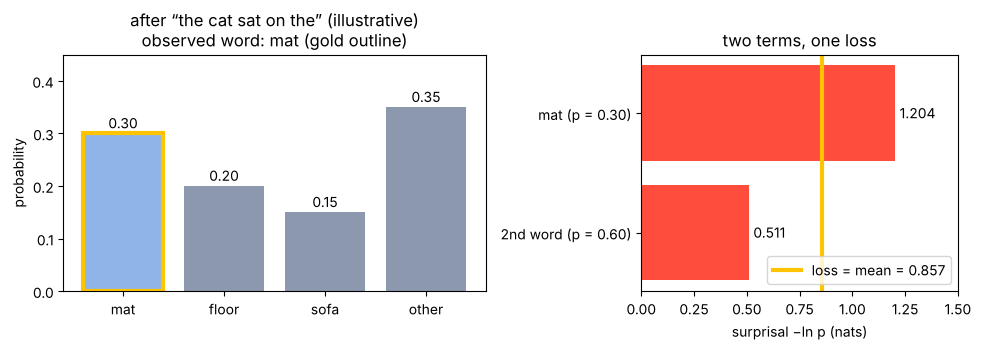

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [4, 3]})
bars = a1.bar(words, p, color=[STEEL, MUTED, MUTED, MUTED])
bars[0].set_edgecolor(GOLD); bars[0].set_linewidth(3)
for b, pk in zip(bars, p):
    a1.text(b.get_x() + b.get_width() / 2, pk + 0.01, f"{pk:.2f}", ha="center")
a1.set_ylim(0, 0.45); a1.set_ylabel("probability")
a1.set_title("after “the cat sat on the” (illustrative)\nobserved word: mat (gold outline)")
a2.barh(["mat (p = 0.30)", "2nd word (p = 0.60)"], [s_mat, s_2], color=CORAL)
a2.axvline(L_words, color=GOLD, lw=3, label=f"loss = mean = {L_words:.3f}")
for k, v in enumerate([s_mat, s_2]):
    a2.text(v + 0.02, k, f"{v:.3f}", va="center")
a2.set_xlim(0, 1.5); a2.set_xlabel("surprisal −ln p (nats)"); a2.invert_yaxis()
a2.set_title("two terms, one loss"); a2.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Part 4 · The bet, the myth and the check question

### Step 9: the bet board
Darts don't work for words: a dart carries no probabilities. So picture a bet. Spread one stack of chips (probability, not money) across four words. The true word is revealed, and you pay −ln(your share on it).

share 0.9  on the true word -> pay -ln 0.9 = 0.105
share 0.5  on the true word -> pay -ln 0.5 = 0.693
share 0.1  on the true word -> pay -ln 0.1 = 2.303
share 0.01 on the true word -> pay -ln 0.01 = 4.605
The less you backed the truth, the faster the bill grows.


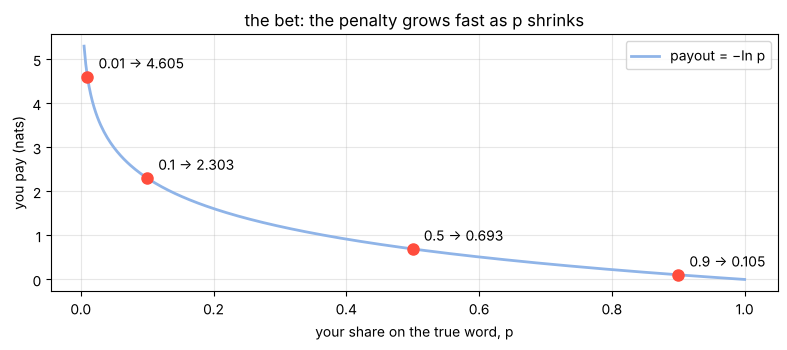

In [14]:
shares = [0.9, 0.5, 0.1, 0.01]
payouts = [surprisal(s) for s in shares]
for s, pay in zip(shares, payouts):
    print(f"share {fmt(s):4s} on the true word -> pay -ln {fmt(s)} = {pay:.3f}")
assert [round(v, 3) for v in payouts] == [0.105, 0.693, 2.303, 4.605]
assert np.all(np.diff(payouts) > 0)
print("The less you backed the truth, the faster the bill grows.")

ps = np.linspace(0.005, 1, 400)
plt.figure(figsize=(8, 3.6))
plt.plot(ps, surprisal(ps), color=STEEL, lw=2, label="payout = −ln p")
plt.plot(shares, payouts, "o", color=CORAL, ms=8)
for s, pay in zip(shares, payouts):
    plt.annotate(f"{fmt(s)} → {pay:.3f}", (s, pay), textcoords="offset points", xytext=(8, 6))
plt.xlabel("your share on the true word, p"); plt.ylabel("you pay (nats)")
plt.title("the bet: the penalty grows fast as p shrinks")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.show()

### Step 10: the myth, "the loss counts wrong answers"
There is something to it: a perfect fit has zero squared error, and a model that puts all its probability on the observed word has zero cross-entropy. But the observed word can be the model's top choice, at 0.45, and still pay.

In [15]:
print(f"perfect fit: gap 0 -> squared error {0 ** 2}")
print(f"all probability on the observed word: -ln 1 = {abs(surprisal(1.0)):.0f}")
assert surprisal(1.0) == 0
myth = surprisal(0.45)
print(f"top choice at 0.45, and it IS the observed word: -ln 0.45 = {myth:.3f} nats")
assert round(myth, 3) == 0.799 and myth > 0
print("The loss is a penalty that training pushes down. It is not a count of mistakes.")

perfect fit: gap 0 -> squared error 0
all probability on the observed word: -ln 1 = 0
top choice at 0.45, and it IS the observed word: -ln 0.45 = 0.799 nats
The loss is a penalty that training pushes down. It is not a count of mistakes.


### Check question
A batch has two terms. The model gives the observed word probability 0.25 the first time and 0.50 the second. (a) What is each term's surprisal? (b) What is the loss? (c) If the first probability rises to 0.40, does the loss go down?

In [16]:
t1, t2 = surprisal(0.25), surprisal(0.50)
L1 = (t1 + t2) / 2
t1b = surprisal(0.40)
L2 = (t1b + t2) / 2
print(f"(a) -ln 0.25 = {t1:.3f},  -ln 0.50 = {t2:.3f} nats")
print(f"(b) L = ({t1:.3f} + {t2:.3f}) / 2 = {L1:.3f} nats")
print(f"(c) -ln 0.40 = {t1b:.3f};  L = ({t1b:.3f} + {t2:.3f}) / 2 = {L2:.3f} nats  ->  {'yes, the loss goes down' if L2 < L1 else 'no'}")
assert round(t1, 3) == 1.386 and round(t2, 3) == 0.693
assert round(L1, 3) == 1.040 and round(t1b, 3) == 0.916 and round(L2, 3) == 0.805 and L2 < L1

(a) -ln 0.25 = 1.386,  -ln 0.50 = 0.693 nats
(b) L = (1.386 + 0.693) / 2 = 1.040 nats
(c) -ln 0.40 = 0.916;  L = (0.916 + 0.693) / 2 = 0.805 nats  ->  yes, the loss goes down


## Part 5 · Try it yourself
Change the values in the next cells and re-run them. The self-checks tell you whether your own hand calculation matches.

1. Pick your own W and β for the three dots and compute the mean squared error by hand. Can you beat 1/18?
2. Change the probability on mat and watch its surprisal change.
3. Compute the loss for three words you choose, then e to that loss, and check it against perplexity.

In [17]:
my_W, my_beta = F(3, 2), F(1, 2)       # 1. your knobs (fractions keep it exact; F(1, 3) is one third)
my_mse = None                          #    your hand answer, e.g. 1/12 ~ 0.083

*_, L_mine = mse_by_hand("yours", my_W, my_beta, frac(my_W), frac(my_beta))
if my_mse is not None:
    print("your answer matches" if np.isclose(float(my_mse), float(L_mine), atol=0.001) else f"not quite: the worksheet gives {frac(L_mine)}")
print("you beat 1/18!" if L_mine < LB else ("you found the least-squares fit" if L_mine == LB else f"{frac(L_mine)} is above 1/18: line B still wins"))
assert L_mine >= LB                    # nobody beats the least-squares fit

Line yours: W = 3/2, beta = 1/2
  u = 1: y-hat = 3/2 x 1 + 1/2 = 1.5 + 1/2 = 2
  u = 2: y-hat = 3/2 x 2 + 1/2 = 3 + 1/2 = 7/2
  u = 3: y-hat = 3/2 x 3 + 1/2 = 4.5 + 1/2 = 5
  error: 2 - 2 = 0
  error: 4 - 7/2 = +1/2
  error: 5 - 5 = 0
  square: 0^2 = 0
  square: (1/2)^2 = 1/4
  square: 0^2 = 0
  add: 0 + 1/4 + 0 = 1/4
  divide by N = 3: MSE = (1/4) / 3 = 1/12 ~ 0.083

1/12 is above 1/18: line B still wins


In [18]:
my_p_mat = 0.30                        # 2. the probability on mat: try 0.45, 0.60, 0.90, 0.01
my_surprisal = None                    #    your hand answer for -ln my_p_mat

s = surprisal(my_p_mat)
print(f"mat at {fmt(my_p_mat)}: surprisal -ln {fmt(my_p_mat)} = {s:.3f} nats")
for pk in sorted({0.01, 0.1, 0.30, 0.5, 0.9, my_p_mat}):
    print(f"  p = {fmt(pk):5s} {'#' * int(round(10 * surprisal(pk))):48s} {surprisal(pk):.3f}{'   <- yours' if pk == my_p_mat else ''}")
if my_surprisal is not None:
    print("your answer matches" if np.isclose(my_surprisal, s, atol=0.001) else f"not quite: -ln {fmt(my_p_mat)} = {s:.3f}")
assert 0 < my_p_mat <= 1 and s >= 0
if my_p_mat == 0.30:
    assert round(s, 3) == 1.204

mat at 0.3: surprisal -ln 0.3 = 1.204 nats
  p = 0.01  ##############################################   4.605
  p = 0.1   #######################                          2.303
  p = 0.3   ############                                     1.204   <- yours
  p = 0.5   #######                                          0.693
  p = 0.9   #                                                0.105


In [19]:
my_probs = [0.30, 0.60, 0.45]          # 3. the probability on each observed word (three words)
my_loss, my_perplexity = None, None    #    your hand answers

terms3 = [surprisal(pk) for pk in my_probs]
L3 = np.mean(terms3)
ppl3 = np.exp(L3)
print(" + ".join(f"{t:.3f}" for t in terms3) + f" = {sum(terms3):.3f};  / {len(terms3)} = loss {L3:.3f} nats")
print("(the terms are printed rounded; the sum uses the unrounded values)")
print(f"perplexity e^{L3:.3f} = {ppl3:.2f}  (1 / geometric mean of the probabilities = {1 / np.prod(my_probs) ** (1 / len(my_probs)):.2f})")
if my_loss is not None:
    print("loss: matches" if np.isclose(my_loss, L3, atol=0.001) else f"loss: not quite, {L3:.3f}")
if my_perplexity is not None:
    print("perplexity: matches" if np.isclose(my_perplexity, ppl3, atol=0.01) else f"perplexity: not quite, {ppl3:.2f}")
assert np.isclose(ppl3, 1 / np.prod(my_probs) ** (1 / len(my_probs)))
if my_probs == [0.30, 0.60, 0.45]:
    assert round(sum(terms3), 3) == 2.513 and round(L3, 3) == 0.838 and round(ppl3, 2) == 2.31

1.204 + 0.511 + 0.799 = 2.513;  / 3 = loss 0.838 nats
(the terms are printed rounded; the sum uses the unrounded values)
perplexity e^0.838 = 2.31  (1 / geometric mean of the probabilities = 2.31)


In [20]:
print("All Episode 7 checks passed.")

All Episode 7 checks passed.
